In [ ]:
# ============================================================
#  Reflective-CXR | Phase A: Visual Domain Adaptation
#  Task: Fine-tune ViT on NIH ChestX-ray14 (3.5k Prototype)
#  Storage: Institutional Google Drive
# ============================================================

!pip install -q transformers datasets torch torchvision accelerate kaggle tqdm scikit-learn matplotlib
print("Dependencies installed.")

from google.colab import drive
import os

# Mount College Google Drive
drive.mount('/content/drive')

# Create persistent storage directory
DRIVE_SAVE_DIR = '/content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder'
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
print(f"Model checkpoints will be saved permanently to: {DRIVE_SAVE_DIR}")

Dependencies installed.
Mounted at /content/drive
Model checkpoints will be saved permanently to: /content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder


In [ ]:
import torch
from google.colab import userdata
import os

# 1. Hardware Verification
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"Hardware locked: {torch.cuda.get_device_name(0)}")
else:
    raise SystemError("GPU NOT FOUND. Change runtime type to T4 GPU.")

# 2. Kaggle Authentication
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
print("Credentials loaded.")

Hardware locked: Tesla T4
Credentials loaded.


In [ ]:
print("Downloading 224x224 NIH Chest X-ray dataset...")
!kaggle datasets download -d khanfashee/nih-chest-x-ray-14-224x224-resized
print("Unzipping dataset...")
!unzip -q nih-chest-x-ray-14-224x224-resized.zip -d nih_data
print("Dataset ready in local runtime.")

Dataset URL: https://www.kaggle.com/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized
License(s): CC0-1.0
100% 2.30G/2.30G [02:29<00:00, 16.5MB/s]

Unzipping dataset...
Dataset ready in local runtime.


In [ ]:
import glob
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split

png_files = glob.glob('/content/nih_data/**/*.png', recursive=True)
IMG_DIR = os.path.dirname(png_files[0])
CSV_PATH = '/content/nih_data/Data_Entry_2017.csv'

df = pd.read_csv(CSV_PATH)
df['labels_list'] = df['Finding Labels'].apply(lambda x: x.split('|'))

mlb = MultiLabelBinarizer()
label_matrix = mlb.fit_transform(df['labels_list'])
ALL_CLASSES = list(mlb.classes_)
NUM_CLASSES = len(ALL_CLASSES)

df_labels = pd.DataFrame(label_matrix, columns=ALL_CLASSES)
df_final = pd.concat([df['Image Index'], df_labels], axis=1)

# The 3,500 sample subset for rapid validation
df_sample = df_final.sample(3500, random_state=42)
train_df, val_df = train_test_split(df_sample, test_size=0.1, random_state=42)

print(f"Classes ({NUM_CLASSES}): {ALL_CLASSES}")
print(f"Training subset: {len(train_df)} images | Validation subset: {len(val_df)} images")

Classes (15): ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'No Finding', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']
Training subset: 3150 images | Validation subset: 350 images


In [ ]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class NIHAdaptationDataset(Dataset):
    def __init__(self, dataframe, img_dir, classes, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.classes = classes
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Image Index']
        img_path = os.path.join(self.img_dir, img_name)

        try:
            image = Image.open(img_path).convert('RGB')
        except Exception:
            image = Image.new('RGB', (224, 224), (0, 0, 0))

        labels = torch.tensor(
            self.df.loc[idx, self.classes].values.astype(float),
            dtype=torch.float32
        )
        if self.transform:
            image = self.transform(image)
        return image, labels

# Strict medical augmentations (no horizontal flips)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_loader = DataLoader(NIHAdaptationDataset(train_df, IMG_DIR, ALL_CLASSES, train_transform), batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(NIHAdaptationDataset(val_df,   IMG_DIR, ALL_CLASSES, val_transform),   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print("DataLoaders initialized.")

DataLoaders initialized.


In [ ]:
import torch.nn as nn
import torch.optim as optim
from transformers import ViTForImageClassification

# Swap the ImageNet head for the 14-class medical head
# (This downloads the public weights automatically, no HF token required)
model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True,
    problem_type="multi_label_classification"
)
model = model.to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=3, eta_min=1e-6)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

EPOCHS = 10
train_losses, val_losses, val_aucs = [], [], []
print("ViT architecture and optimizers locked.")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                         
------------------+----------+-----------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000]) vs model:torch.Size([15])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000, 768]) vs model:torch.Size([15, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


ViT architecture and optimizers locked.


/tmp/ipykernel_5316/255301107.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


In [ ]:
import numpy as np
from tqdm import tqdm
from sklearn.metrics import roc_auc_score
from transformers import ViTImageProcessor

print("Commencing Phase A Prototype Training...")
processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")

for epoch in range(EPOCHS):
    # --- TRAINING ---
    model.train()
    running_loss = 0.0
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]")

    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()

        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            outputs = model(pixel_values=images)
            loss = criterion(outputs.logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        loop.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = running_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # --- VALIDATION ---
    model.eval()
    val_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]"):
            images, labels = images.to(device), labels.to(device)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                outputs = model(pixel_values=images)
                loss = criterion(outputs.logits, labels)

            val_loss += loss.item()
            all_preds.append(torch.sigmoid(outputs.logits).cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    all_preds = np.vstack(all_preds)
    all_labels = np.vstack(all_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds, average='macro')
    except ValueError:
        auc = 0.0
    val_aucs.append(auc)
    scheduler.step()

    print(f"\nEpoch {epoch+1} Metrics | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | AUC: {auc:.4f}")

    # --- SAVE TO GOOGLE DRIVE ---
    print(f"Saving Epoch {epoch+1} backbone directly to Google Drive...")
    epoch_save_path = f"{DRIVE_SAVE_DIR}/checkpoint_epoch_{epoch+1}"

    # Save ONLY the backbone (model.vit) and processor for Phase B
    model.vit.save_pretrained(epoch_save_path)
    processor.save_pretrained(epoch_save_path)
    print(f"Saved safely to: {epoch_save_path}")

print("Phase A Prototype Complete. The adapted vision encoder is ready for Phase B.")

Commencing Phase A Prototype Training...


Epoch 1/10 [Train]:   0%|          | 0/99 [00:00<?, ?it/s]/tmp/ipykernel_5316/2834863435.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
Epoch 1/10 [Val]:   0%|          | 0/11 [00:00<?, ?it/s]/tmp/ipykernel_5316/2834863435.py:41: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
Epoch 1/10 [Val]: 100%|██████████| 11/11 [00:01<00:00,  5.89it/s]


Epoch 1 Metrics | Train Loss: 0.1984 | Val Loss: 0.1973 | AUC: nan
Saving Epoch 1 backbone directly to Google Drive...



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved safely to: /content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder/checkpoint_epoch_1


... (39 outputs left out)

Epoch 10/10 [Train]:   0%|          | 0/99 [00:00<?, ?it/s]/tmp/ipykernel_5316/2834863435.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
Epoch 10/10 [Val]:   0%|          | 0/11 [00:00<?, ?it/s]/tmp/ipykernel_5316/2834863435.py:41: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
Epoch 10/10 [Val]: 100%|██████████| 11/11 [00:01<00:00,  7.97it/s]
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(



Epoch 10 Metrics | Train Loss: 0.1587 | Val Loss: 0.1924 | AUC: nan
Saving Epoch 10 backbone directly to Google Drive...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved safely to: /content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder/checkpoint_epoch_10
Phase A Prototype Complete. The adapted vision encoder is ready for Phase B.


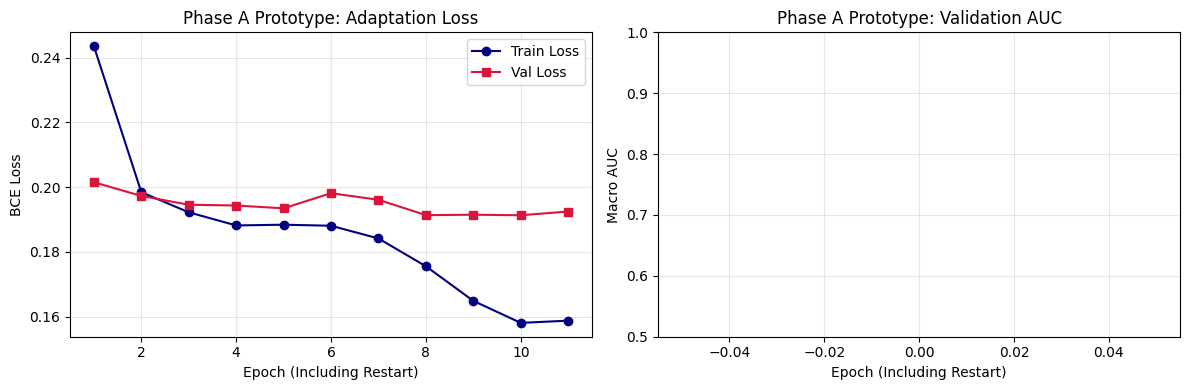

Plot permanently saved to Drive: /content/drive/MyDrive/Thesis_CXR/phaseA_prototype_curves.png


In [ ]:
import matplotlib.pyplot as plt

# Dynamically find the minimum length just in case the lists are uneven from the crash
actual_epochs = min(len(train_losses), len(val_losses), len(val_aucs))
x_axis = range(1, actual_epochs + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Plotting with dynamic x_axis
ax1.plot(x_axis, train_losses[:actual_epochs], 'o-', label='Train Loss', color='navy')
ax1.plot(x_axis, val_losses[:actual_epochs], 's-', label='Val Loss', color='crimson')
ax1.set_xlabel("Epoch (Including Restart)")
ax1.set_ylabel("BCE Loss")
ax1.set_title("Phase A Prototype: Adaptation Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(x_axis, val_aucs[:actual_epochs], 'o-', color='forestgreen')
ax2.set_xlabel("Epoch (Including Restart)")
ax2.set_ylabel("Macro AUC")
ax2.set_title("Phase A Prototype: Validation AUC")
ax2.set_ylim(0.5, 1.0)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plot_path = f"/content/drive/MyDrive/Thesis_CXR/phaseA_prototype_curves.png"
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"Plot permanently saved to Drive: {plot_path}")